In [ ]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

In [ ]:
# Load the Charlotte transit network data
nodes = pd.read_csv("nodes.csv", dtype={"stop_id": str})
edges = pd.read_csv("edges.csv", dtype={"source": str, "target": str})

# Check how many stops and connections we have
print("Number of stops:", len(nodes))
print("Number of connections:", len(edges))

# Show the first five stops
nodes.head()

Number of stops: 2899
Number of connections: 3153


,stop_id,stop_name,lat,lon,mode,routes
0,00001,7th St Station,35.227375,-80.838088,rail,501
1,00002,CTC Station,35.225336,-80.840975,rail,501
2,00003,3rd/ Convention Center Station,35.223631,-80.843237,rail,501
3,00004,Brooklyn Village Station,35.221319,-80.847066,rail,501
4,00005,Carson Station,35.218822,-80.850947,rail,501


In [ ]:
# Create an undirected network
G = nx.Graph()

# Add all transit stops as nodes
G.add_nodes_from(nodes["stop_id"])

# Add connections between stops
for _, row in edges.iterrows():
    G.add_edge(row["source"], row["target"])

# Display basic network information
print("Total nodes:", G.number_of_nodes())
print("Total edges:", G.number_of_edges())
print("Connected components:", nx.number_connected_components(G))
print("Largest connected component:", len(max(nx.connected_components(G), key=len)))

Total nodes: 2899
Total edges: 3153
Connected components: 3
Largest connected component: 2849


In [ ]:
import random

# Make a copy so we don't change the original network
G_random = G.copy()

# Use a seed so we can repeat the same experiment
random.seed(42)

# Randomly select 10% of stops
number_to_remove = int(G.number_of_nodes() * 0.10)
stops_to_remove = random.sample(list(G.nodes()), number_to_remove)

# Remove the selected stops
G_random.remove_nodes_from(stops_to_remove)

# Measure the largest remaining connected group
largest_group = len(max(nx.connected_components(G_random), key=len))

# Display the results
print("Stops removed:", number_to_remove)
print("Stops remaining:", G_random.number_of_nodes())
print("Largest connected group:", largest_group)
print("Percentage of original network still connected:",
      round(largest_group / G.number_of_nodes() * 100, 2), "%")

Stops removed: 289
Stops remaining: 2610
Largest connected group: 1533
Percentage of original network still connected: 52.88 %


In [ ]:
# Make a copy of the original network
G_degree = G.copy()

# Find the stops with the most connections
ranked_stops = sorted(
    G.degree(),
    key=lambda x: x[1],
    reverse=True
)

# Select the top 10% most connected stops
number_to_remove = int(G.number_of_nodes() * 0.10)
important_stops = [stop for stop, degree in ranked_stops[:number_to_remove]]

# Remove those important stops
G_degree.remove_nodes_from(important_stops)

# Find the largest connected group remaining
largest_group_degree = len(
    max(nx.connected_components(G_degree), key=len)
)

# Show the results
print("Stops removed:", number_to_remove)
print("Stops remaining:", G_degree.number_of_nodes())
print("Largest connected group:", largest_group_degree)
print("Percentage of original network still connected:",
      round(largest_group_degree / G.number_of_nodes() * 100, 2), "%")

Stops removed: 289
Stops remaining: 2610
Largest connected group: 86
Percentage of original network still connected: 2.97 %


In [ ]:
import random
import pandas as pd
import networkx as nx

results = []

number_to_remove = int(G.number_of_nodes() * 0.10)

for trial in range(1, 101):

    # Use a different repeatable random seed
    rng = random.Random(42 + trial)

    # Start with the original network
    test_network = G.copy()

    # Randomly select 10% of the stops
    selected_stops = rng.sample(
        list(G.nodes()),
        number_to_remove
    )

    # Remove the selected stops
    test_network.remove_nodes_from(selected_stops)

    # Measure the largest connected group
    largest_group = len(
        max(nx.connected_components(test_network), key=len)
    )

    percentage = (
        largest_group / G.number_of_nodes()
    ) * 100

    results.append({
        "Trial": trial,
        "Stops Removed": number_to_remove,
        "Largest Connected Group": largest_group,
        "Percentage Connected": round(percentage, 2)
    })

# Display results
results_df = pd.DataFrame(results)

display(results_df)

print(
    "Average percentage connected:",
    round(results_df["Percentage Connected"].mean(), 2),
    "%"
)

,Trial,Stops Removed,Largest Connected Group,Percentage Connected
0,1,289,1264,43.60
1,2,289,1277,44.05
2,3,289,1315,45.36
3,4,289,1575,54.33
4,5,289,997,34.39
...,...,...,...,...
95,96,289,1262,43.53
96,97,289,1410,48.64
97,98,289,1386,47.81
98,99,289,1138,39.25


Average percentage connected: 46.93 %


In [ ]:
# Betweenness-based targeted removal

import networkx as nx

# Calculate betweenness centrality
# Approximation keeps the calculation manageable
betweenness = nx.betweenness_centrality(
    G,
    k=200,
    normalized=True,
    seed=42
)

# Rank stops from highest to lowest betweenness
ranked_stops = sorted(
    betweenness,
    key=betweenness.get,
    reverse=True
)

# Remove the top 10% of stops
number_to_remove = int(G.number_of_nodes() * 0.10)

G_betweenness = G.copy()

G_betweenness.remove_nodes_from(
    ranked_stops[:number_to_remove]
)

# Measure the largest connected group
largest_group = len(
    max(
        nx.connected_components(G_betweenness),
        key=len
    )
)

percentage = (
    largest_group / G.number_of_nodes()
) * 100

print("Stops removed:", number_to_remove)
print("Stops remaining:", G_betweenness.number_of_nodes())
print("Largest connected group:", largest_group)
print(
    "Percentage of original network still connected:",
    round(percentage, 2),
    "%"
)

Stops removed: 289
Stops remaining: 2610
Largest connected group: 2002
Percentage of original network still connected: 69.06 %


In [ ]:
# Compare the top 10 stops by degree and betweenness

stop_names = dict(
    zip(nodes["stop_id"], nodes["stop_name"])
)

degree_ranking = sorted(
    G.degree(),
    key=lambda x: x[1],
    reverse=True
)

print("TOP 10 STOPS BY DEGREE")
for stop, score in degree_ranking[:10]:
    print(stop_names.get(stop, stop), "-", score)

print("\nTOP 10 STOPS BY BETWENNESS")
for stop in ranked_stops[:10]:
    print(
        stop_names.get(stop, stop),
        "-",
        round(betweenness[stop], 5)
    )

TOP 10 STOPS BY DEGREE
College St & 11th St - 12
Albemarle Rd & Lawyers Rd Park and Ride - 9
Transit Center- Bay X - 9
Church St & 9th St - 9
Matthews Park & Ride - 9
4th St & McDowell St - 8
3rd St & Davidson St - 7
Brevard St & Martin Luther King Jr Blvd - 7
Charlotte Douglas Airport - 6
Randolph Rd & Billingsley Rd - 6

TOP 10 STOPS BY BETWENNESS
4th St & McDowell St - 0.37052
Transit Center- Bay X - 0.27639
4th St & Davidson St - 0.22328
Randolph Rd & Billingsley Rd - 0.21257
4th St & Torrence St - 0.18822
4th St & Kings Dr - 0.18794
4th St & Hawthorne Ln - 0.18633
3rd St & Tryon St - 0.17267
Randolph Rd & Wendwood Ln - 0.16772
Providence Rd & Wendover Rd - 0.15638


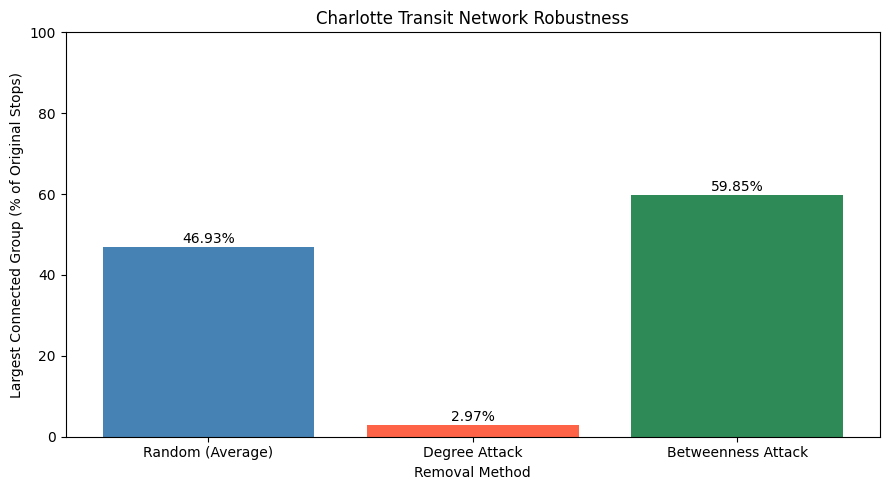

In [ ]:
import matplotlib.pyplot as plt

methods = [
    "Random (Average)",
    "Degree Attack",
    "Betweenness Attack"
]

percentages = [46.93, 2.97, 59.85]

plt.figure(figsize=(9, 5))

bars = plt.bar(
    methods,
    percentages,
    color=["steelblue", "tomato", "seagreen"]
)

plt.title("Charlotte Transit Network Robustness")
plt.ylabel("Largest Connected Group (% of Original Stops)")
plt.xlabel("Removal Method")
plt.ylim(0, 100)

for bar, value in zip(bars, percentages):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

Method,Betweenness (Approx.),Degree,Random
Removal %,,,
5,81.13,17.28,80.07
10,69.06,2.97,48.57
15,30.39,1.66,23.10
20,19.04,1.66,14.16
25,8.52,1.59,7.56


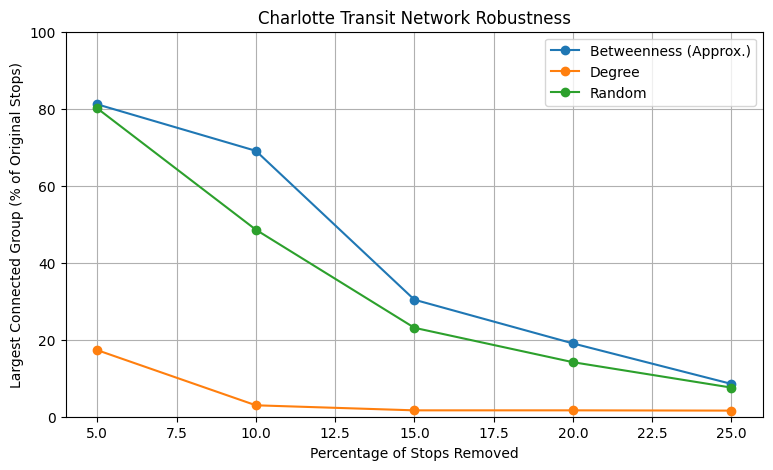

In [ ]:
import random
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

removal_levels = [5, 10, 15, 20, 25]
all_results = []

original_nodes = list(G.nodes())
total_nodes = G.number_of_nodes()

for percent in removal_levels:
    number_to_remove = int(total_nodes * percent / 100)

    # Random removal: 10 trials
    for trial in range(10):
        rng = random.Random(42 + trial)

        test_graph = G.copy()
        removed = rng.sample(original_nodes, number_to_remove)
        test_graph.remove_nodes_from(removed)

        largest = max(
            (len(c) for c in nx.connected_components(test_graph)),
            default=0
        )

        all_results.append({
            "Removal %": percent,
            "Method": "Random",
            "Trial": trial + 1,
            "Largest Group %": largest / total_nodes * 100
        })

    # Degree attack using original rankings
    degree_graph = G.copy()
    degree_nodes = [
        node for node, degree in
        sorted(G.degree(), key=lambda x: x[1], reverse=True)
    ]

    degree_graph.remove_nodes_from(
        degree_nodes[:number_to_remove]
    )

    largest = max(
        (len(c) for c in nx.connected_components(degree_graph)),
        default=0
    )

    all_results.append({
        "Removal %": percent,
        "Method": "Degree",
        "Trial": 1,
        "Largest Group %": largest / total_nodes * 100
    })

    # Betweenness attack using existing approximate rankings
    bet_graph = G.copy()
    bet_graph.remove_nodes_from(
        ranked_stops[:number_to_remove]
    )

    largest = max(
        (len(c) for c in nx.connected_components(bet_graph)),
        default=0
    )

    all_results.append({
        "Removal %": percent,
        "Method": "Betweenness (Approx.)",
        "Trial": 1,
        "Largest Group %": largest / total_nodes * 100
    })

# Create summary table
full_results = pd.DataFrame(all_results)

summary = (
    full_results
    .groupby(["Removal %", "Method"])["Largest Group %"]
    .mean()
    .unstack()
)

display(summary.round(2))

# Plot results
plt.figure(figsize=(9, 5))

for method in summary.columns:
    plt.plot(
        summary.index,
        summary[method],
        marker="o",
        label=method
    )

plt.title("Charlotte Transit Network Robustness")
plt.xlabel("Percentage of Stops Removed")
plt.ylabel("Largest Connected Group (% of Original Stops)")
plt.ylim(0, 100)
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
print("Top 10 stops selected for degree attack:")
for stop in important_stops[:10]:
    name = nodes.loc[nodes["stop_id"] == stop, "stop_name"]
    print(stop, name.iloc[0] if not name.empty else "Unknown")

print("\nTop 10 stops selected for betweenness attack:")
for stop in ranked_stops[:10]:
    name = nodes.loc[nodes["stop_id"] == stop, "stop_name"]
    print(stop, name.iloc[0] if not name.empty else "Unknown")

Top 10 stops selected for degree attack:
25410 College St & 11th St
00285 Albemarle Rd & Lawyers Rd Park and Ride
32550 Transit Center- Bay X
37410 Church St & 9th St
42355 Matthews Park & Ride
45768 4th St & McDowell St
08230 3rd St & Davidson St
25270 Brevard St & Martin Luther King Jr Blvd
23520 Charlotte Douglas Airport
23760 Randolph Rd & Billingsley Rd

Top 10 stops selected for betweenness attack:
45768 4th St & McDowell St
32550 Transit Center- Bay X
07380 4th St & Davidson St
23760 Randolph Rd & Billingsley Rd
07500 4th St & Torrence St
07480 4th St & Kings Dr
07520 4th St & Hawthorne Ln
45010 3rd St & Tryon St
23790 Randolph Rd & Wendwood Ln
22450 Providence Rd & Wendover Rd


In [ ]:
# Calculate exact betweenness centrality
exact_betweenness = nx.betweenness_centrality(G)

# Rank stops by exact betweenness
exact_ranked_stops = sorted(
    exact_betweenness,
    key=exact_betweenness.get,
    reverse=True
)

# Remove the top 10% of stops
number_to_remove = int(G.number_of_nodes() * 0.10)

G_exact = G.copy()
G_exact.remove_nodes_from(
    exact_ranked_stops[:number_to_remove]
)

# Measure the largest connected group
largest_group = len(
    max(nx.connected_components(G_exact), key=len)
)

percentage = largest_group / G.number_of_nodes() * 100

print("Stops removed:", number_to_remove)
print("Largest connected group:", largest_group)
print("Percentage of original network still connected:", round(percentage, 2), "%")

Stops removed: 289
Largest connected group: 1735
Percentage of original network still connected: 59.85 %


In [ ]:
# Calculate the percentage of original stop pairs
# that can still reach each other after removals.

def pair_reachability(graph, original_count):
    connected_pairs = sum(
        size * (size - 1) // 2
        for size in (
            len(component)
            for component in nx.connected_components(graph)
        )
    )

    original_pairs = original_count * (original_count - 1) // 2

    return round(connected_pairs / original_pairs * 100, 2)


original_count = G.number_of_nodes()

# Degree attack
degree_reachability = pair_reachability(G_degree, original_count)

# Exact betweenness attack
betweenness_reachability = pair_reachability(G_exact, original_count)

# Random removal: 100 trials
random_reachability = []

for trial in range(1, 101):
    rng = random.Random(42 + trial)
    test_graph = G.copy()

    removed_stops = rng.sample(
        list(G.nodes()),
        int(original_count * 0.10)
    )

    test_graph.remove_nodes_from(removed_stops)

    random_reachability.append(
        pair_reachability(test_graph, original_count)
    )

print("PAIR REACHABILITY AFTER 10% STOP REMOVAL")
print("Random (100-trial average):", round(sum(random_reachability) / 100, 2), "%")
print("Degree attack:", degree_reachability, "%")
print("Exact betweenness attack:", betweenness_reachability, "%")

PAIR REACHABILITY AFTER 10% STOP REMOVAL
Random (100-trial average): 23.11 %
Degree attack: 0.67 %
Exact betweenness attack: 36.71 %


In [ ]:
import numpy as np
import pandas as pd

# Results from the removal-percentage experiment
# Each number represents the percentage of original stops
# remaining in the largest connected group.

removal_percentages = [0, 5, 10, 15, 20, 25]

# Original network: 2849 of 2899 stops in largest group
initial_retention = 2849 / 2899 * 100

random_retention = [initial_retention, 80.07, 48.57, 23.10, 14.16, 7.56]
degree_retention = [initial_retention, 17.28, 2.97, 1.66, 1.66, 1.59]
betweenness_retention = [initial_retention, 81.13, 69.06, 30.39, 19.04, 8.52]

# Calculate area under each retention curve
# Divide by 25 so results are on a percentage scale
random_area = np.trapezoid(random_retention, removal_percentages) / 25
degree_area = np.trapezoid(degree_retention, removal_percentages) / 25
betweenness_area = np.trapezoid(betweenness_retention, removal_percentages) / 25

print("RETENTION AREA RESULTS (0% TO 25% REMOVAL)")
print("Random removal:", round(random_area, 2))
print("Degree attack:", round(degree_area, 2))
print("Betweenness attack:", round(betweenness_area, 2))

RETENTION AREA RESULTS (0% TO 25% REMOVAL)
Random removal: 43.76
Degree attack: 14.7
Betweenness attack: 50.6
